<img src="../assets/ga-logo.png" style="float: left; margin: 20px; height: 55px">

# Hyperparameters & GridSearch

---

### About
An introduction to optimizing machine learning models with grid search and pipelines in `scikit-learn`.

### Learning Objectives
- Describe what the terms hyperparameters, GridSearch, and pipeline mean.
- Apply `sklearn`'s `GridSearchCV` object.
- Use attributes of the GridSearch object.
- Describe the pitfalls of searching large hyperparameter spaces.
- Build pipelines.

### Notebook Guide

- Imports and Data Setup
- Data SetUp
- Grid Search
- Pipelines
- A Word of Caution on GridSearching
- Alternative: RandomSearchCV

![](https://snag.gy/aYcCt2.jpg)

# Imports and Data Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV

from sklearn.preprocessing import StandardScaler

from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import mean_absolute_error

In [2]:
# abalone is a marine sea snail 

abalone_colnames = [
    'sex', 'length', 'diameter', 'height', 'whole_weight',
    'shucked_weight', 'viscera_weight', 'shell_weight', 'rings'
]
ab = pd.read_csv('../data/abalone.data', names=abalone_colnames)
ab.head()

,sex,length,diameter,height,whole_weight,shucked_weight,viscera_weight,shell_weight,rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


In [3]:
ab.shape

(4177, 9)

In [4]:
ab.isna().sum()

sex               0
length            0
diameter          0
height            0
whole_weight      0
shucked_weight    0
viscera_weight    0
shell_weight      0
rings             0
dtype: int64

### Let's Whiz Through the Boring Parts
Quickly so as to get to the fun parts, I'll:
* Create our `X` and `y`. We'll be doing a kNN, so can't use `sex`.
* Do a train-test split
* Scale our data

In [5]:
X = ab.drop(columns=['sex', 'rings'])
y = ab['rings']

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=2022)

sc = StandardScaler()
X_train_sc = sc.fit_transform(X_train)
X_test_sc = sc.transform(X_test)

# Grid Search
---
> _Friends don't let friends use Grid Search._

Up until now, we've tuned our tuning parameters either automatically using some `sklearn` tech, or via sloppy loops. `sklearn` gives us some fun tools for automating this process in many cases. Let's demonstrate with a simple kNN first.

In [6]:
# Create a KNN regression model
knn = KNeighborsRegressor()

# Define the values of k (number of neighbors) to test
# Tests: 1, 6, 11, 16, ..., 201
pgrid = {'n_neighbors': np.arange(1,200,5)}

# Use GridSearchCV to test each value of k using cross-validation
# By default, GridSearchCV uses 5-fold cross-validation
gs = GridSearchCV(estimator=knn,
                  param_grid=pgrid,
                  cv=5)

In [7]:
# Run the GridSearchCV
gs.fit(X_train_sc,y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",KNeighborsRegressor()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'n_neighbors': array([ 1, ..., 196])}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with 

In [8]:
# Display the chosen number of neighbors
gs.best_params_

{'n_neighbors': np.int64(31)}

In [9]:
# Return the best model
best_model = gs.best_estimator_

In [10]:
# Predict on a sample abalone
sample_data = [["M", "0.455", "0.365", "0.095", "0.5140", "0.2245", "0.1010" ,"0.150"]]

abalone_colnames.remove("rings")

sample_df = pd.DataFrame(sample_data, columns=abalone_colnames )
sample_df

,sex,length,diameter,height,whole_weight,shucked_weight,viscera_weight,shell_weight
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150


In [21]:
# Transform your sample
sample_df = sample_df.drop(columns=['sex'])
sample_df = sc.transform(sample_df)

In [22]:
# Predict
best_model.predict(sample_df)

array([8.32258065])

In [23]:
# Going deeper to GridSearchCV results
gs.cv_results_

{'mean_fit_time': array([0.01736323, 0.00464193, 0.00352891, 0.00383409, 0.00397094,
        0.00370574, 0.00409563, 0.0052398 , 0.00567396, 0.00413013,
        0.0036056 , 0.00503731, 0.00458097, 0.00396991, 0.0060691 ,
        0.00334001, 0.00438873, 0.00434891, 0.00391396, 0.00369883,
        0.00528185, 0.00597644, 0.00407728, 0.00519927, 0.00360727,
        0.0037717 , 0.00553465, 0.00558225, 0.00649691, 0.00672936,
        0.00530211, 0.00327102, 0.00352422, 0.0044872 , 0.00348759,
        0.00364168, 0.00395616, 0.00355395, 0.00419911, 0.00438682,
        0.0035367 , 0.00392   , 0.00466625, 0.00400273, 0.00504669,
        0.00462302, 0.0042003 , 0.00673342, 0.00609891, 0.00486581,
        0.00396689, 0.00351707, 0.00434883, 0.00503   , 0.00479865,
        0.00393852, 0.00418361, 0.0046653 , 0.00382503, 0.00435058,
        0.00402435, 0.00406837, 0.00410056, 0.00729561, 0.00569828,
        0.00680367, 0.00619825, 0.00427119, 0.00508912, 0.00589816,
        0.00452542, 0.0047725 ,

In [24]:
# Let's beautiful the results
df_gs = pd.DataFrame(gs.cv_results_)
df_gs.head(10)

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_metric,param_n_neighbors,params,split0_test_score,split1_test_score,split2_test_score,mean_test_score,std_test_score,rank_test_score
0,0.017363,0.014588,0.032773,0.011511,manhattan,1,"{'metric': 'manhattan', 'n_neighbors': 1}",-1.943487,-2.010536,-1.963602,-1.972542,0.028093,121
1,0.004642,0.001809,0.017757,0.001779,manhattan,6,"{'metric': 'manhattan', 'n_neighbors': 6}",-1.558589,-1.638889,-1.594508,-1.597329,0.032843,71
2,0.003529,0.000245,0.017563,0.000591,manhattan,11,"{'metric': 'manhattan', 'n_neighbors': 11}",-1.519418,-1.572362,-1.536486,-1.542755,0.022064,31
3,0.003834,0.000058,0.021277,0.001842,manhattan,16,"{'metric': 'manhattan', 'n_neighbors': 16}",-1.497905,-1.561303,-1.522929,-1.527379,0.026073,18
4,0.003971,0.000378,0.024401,0.002084,manhattan,21,"{'metric': 'manhattan', 'n_neighbors': 21}",-1.492018,-1.554096,-1.515143,-1.520419,0.025616,7
5,0.003706,0.000519,0.020058,0.000771,manhattan,26,"{'metric': 'manhattan', 'n_neighbors': 26}",-1.489353,-1.552645,-1.516947,-1.519648,0.025909,5
6,0.004096,0.000334,0.028532,0.001339,manhattan,31,"{'metric': 'manhattan', 'n_neighbors': 31}",-1.480410,-1.554474,-1.514121,-1.516335,0.030277,1
7,0.005240,0.000313,0.035774,0.006048,manhattan,36,"{'metric': 'manhattan', 'n_neighbors': 36}",-1.482599,-1.560212,-1.512612,-1.518474,0.031955,3
8,0.005674,0.000443,0.040415,0.003857,manhattan,41,"{'metric': 'manhattan', 'n_neighbors': 41}",-1.481310,-1.563452,-1.523269,-1.522677,0.033537,10
9,0.004130,0.000738,0.029643,0.004699,manhattan,46,"{'metric': 'manhattan', 'n_neighbors': 46}",-1.489068,-1.567529,-1.522718,-1.526438,0.032139,16


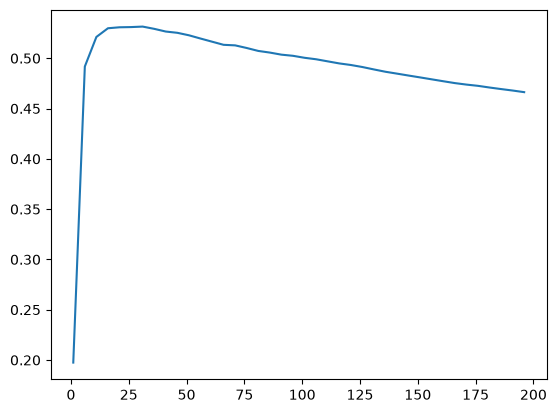

In [15]:
# Plot the relation betweeen number of neighbors and mean test score
plt.plot(df_gs.param_n_neighbors, df_gs.mean_test_score);

This is cool!!! And we actually have `gs.best_estimator_` already fit as our optional model. But there's actually one more piece of efficiency `sklearn` can give us:

## Back to You

Try to find the best `Metric` to use for distance computation.
- You are still using `KNeighborsRegressor`
- You still need to find the best `n_neighbors` at the same time
- Validate your results using mae
- Run 3 folds only

__HINT__: Have a look at [`KNeighborsRegressor`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.pairwise.distance_metrics.html#sklearn.metrics.pairwise.distance_metrics) documentation

In [16]:
#Your Answer Here

In [17]:
# Create a KNN regression model
knn = KNeighborsRegressor()

# Define the parameters to test
pgrid = {
    'n_neighbors': np.arange(1, 202, 5),
    'metric':['manhattan', 'euclidean', 'l1']
}

# Use GridSearchCV to test each combination of your parameters
gs = GridSearchCV(
    estimator = knn,
    param_grid = pgrid,
    scoring = 'neg_mean_absolute_error',
    cv = 3
)

In [18]:
# Run the GridSearchCV
gs.fit(X_train_sc, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",KNeighborsRegressor()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'metric': ['manhattan', 'euclidean', ...], 'n_neighbors': array([ 1, ... 196, 201])}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_absolute_error'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=

In [19]:
# Display the chosen parameters
gs.best_params_

{'metric': 'manhattan', 'n_neighbors': np.int64(31)}

# Validate vs Evaluate: What's the difference?
---

During **validation**, we are still developing the model. We use `cross-validation` or `GridSearchCV` on the **training set** to check whether the model can generalize to data it was not fitted on and to choose hyperparameters.

Comparing training and validation performance can also help us diagnose the model:

- **Good training, poor validation → likely overfitting**
- **Poor training and poor validation → likely underfitting**
- **Good and similar training/validation performance → better generalization**

Once we are happy with the validation results and have chosen our final model, we use the untouched **test set** for one final evaluation.

**Important:** We should not change the model, hyperparameters, or chosen metric based on the test-set result just to improve the test score. If we repeatedly use the test set to make modeling decisions, the test set becomes part of the model-development process, causing **test-set leakage/contamination** and giving us an overly optimistic estimate of performance.

## Sample Workflow

In [20]:
# Validate your model and look for best parameters

knn = KNeighborsRegressor()

pgrid = {
    'n_neighbors': np.arange(1, 50, 5)
}

gs = GridSearchCV(
    estimator=knn,
    param_grid=pgrid,
    cv=3,
    scoring="neg_mean_absolute_error",
    ________=________
)

NameError: name '________' is not defined

In [ ]:
gs.fit(X_train_sc, y_train)

In [ ]:
# Analyse the results of your gridsearch
df_gs = pd.DataFrame(gs.cv_results_)
df_gs

In [ ]:
gs.best_params_

In [ ]:
# Extract the index of the best score
gs.best_index_

In [ ]:
train_score = gs.cv_results_['mean_train_score'][gs.best_index_]
train_score

In [ ]:
validation_score = gs.cv_results_['mean_test_score'][gs.best_index_]
validation_score # "test" here means validation fold

In [ ]:
# Evaluate your model
best_model = ??

y_pred = ??

??

# A Word of Caution on GridSearching

`sklearn` models often have many hyperparameters with many different possible values. It may be tempting to search over a wide variety of them. In general, this is not wise.

<details><summary>Why not?</summary>

- Remember that GridSearch searches over **all possible combinations of hyperparameters in the parameter dictionary!**

Imagine that we had this as our parameter dictionary:

```python
parameter_grid = {
    'n_neighbors': range(1, 151),
    'weights': ['uniform', 'distance', custom_function],
    'algorithm': ['ball_tree', 'kd_tree', 'brute', 'auto'],
    'leaf_size': range(1, 152),
    'metric': ['minkowski', 'euclidean'],
    'p': [1, 2]
}
```

**How many different combinations will need to be tested?**

| Parameter | Number of Chosen Values |
| --- | --- |
| **n_neighbors** | 150 |
| **weights** | 3 |
| **algorithm** | 4 |
| **leaf_size** | 151 |
| **metric** | 2 |
| **p** | 2 |
| <br>_150 \* 3 \* 4 \* 151 \* 2 \* 2 = n combinations_ <br><br>| _1,087,200_ |

If we select `cv = 5`, we would fit 1,087,200 models on five folds, meaning we fit 5,436,000 models!

If you're not careful, GridSearching can quickly scale out of hand computationally.

> **It is extremely important to understand what the hyperparameters do and think critically about what ranges are useful and relevant to your model!**
</details>

## Alternative: `RandomSearchCV`
**Random searching** (aka **stochastic searching**) is a much more recommended method for large parameter spaces. It choses tuning parameter combinations at random to "visit" more of the parameter space without doing an exhaustive search.

Have a look at the visuals in this [article](https://www.geeksforgeeks.org/machine-learning/hyperparameter-tuning)

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

# Interview Question

<details><summary>What is the difference between hyperparameters and statistical parameters?</summary>
    
- Statistical parameters are quantities that a model can learn or estimate. Examples include $\beta_0$ and $\beta_1$ in a linear model.
- Hyperparameters are quantities our model cannot learn, but affect the fit of our model. Examples include $k$ in $k$-nearest neighbors and $alpha$ in regularization.
</details>

---

To the slides!

---